In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find {DATA_PATH.resolve()}. Put USSeatBelts.csv in this folder "
            "or change DATA_PATH at the top of this script."
        )
    return pd.read_csv(DATA_PATH)
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))
    print("\nINFO:")
    df.info()
    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY:\n", df.describe(include="all").T)
df = load_seatbelts()
show_data(df)


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

INFO:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

FIRST SIX ROWS:
    rownames state  year  miles  fatalitie


NUMERICAL VARIABLES: ['rownames', 'year', 'miles', 'fatalities', 'seatbelt', 'income', 'age']
CATEGORICAL VARIABLES: ['state', 'speed65', 'speed70', 'drinkage', 'alcohol', 'enforce']


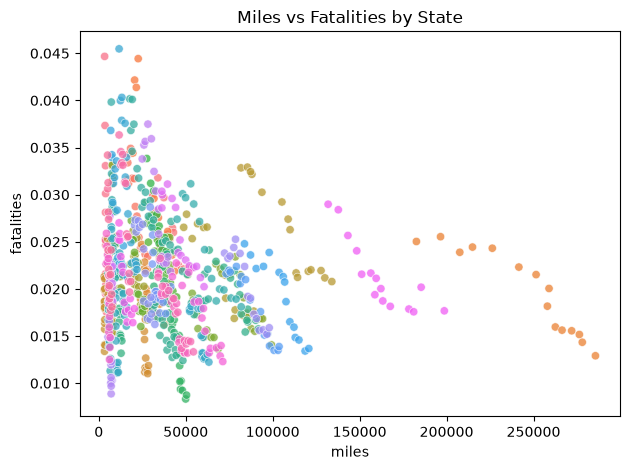

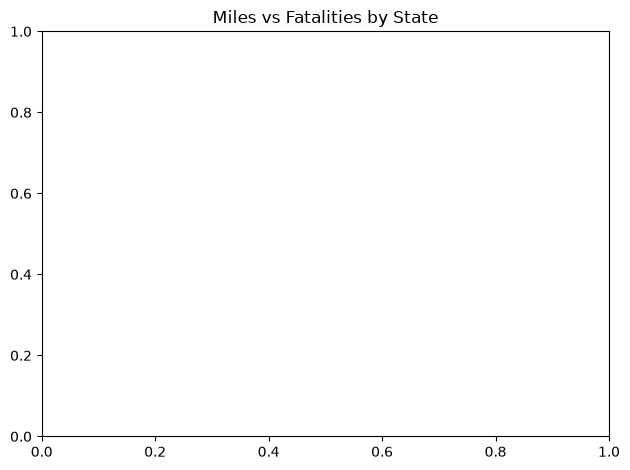

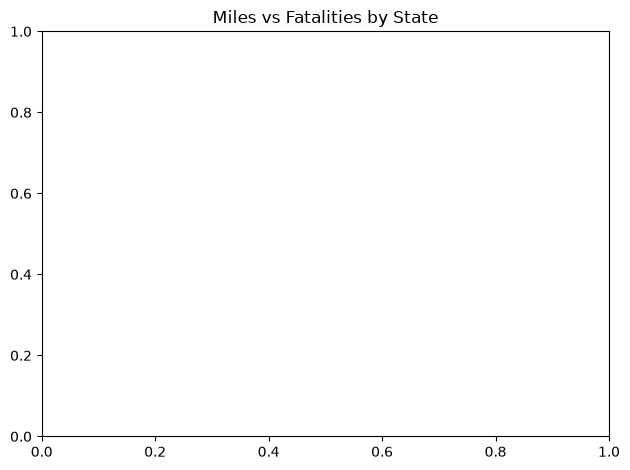

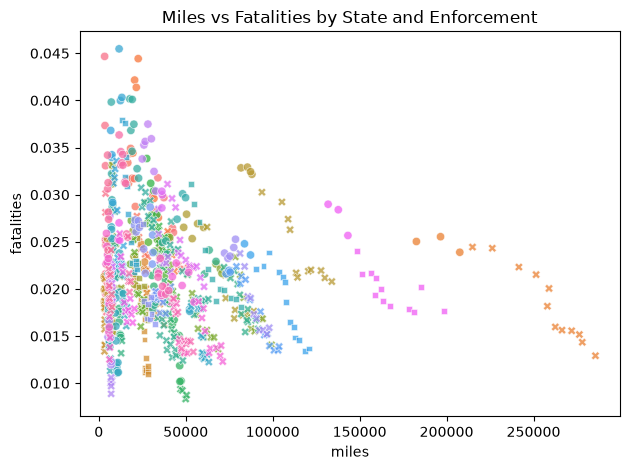

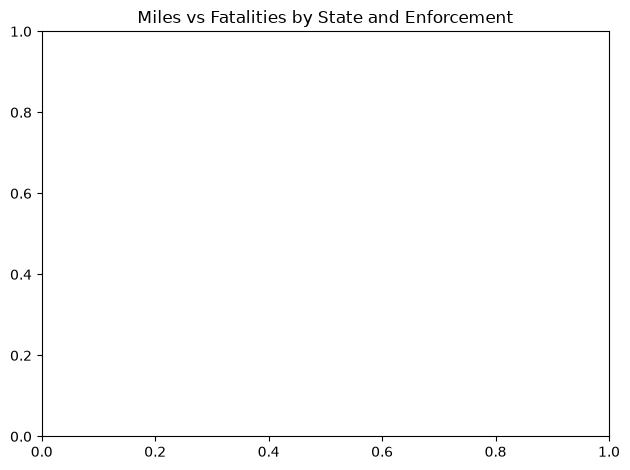

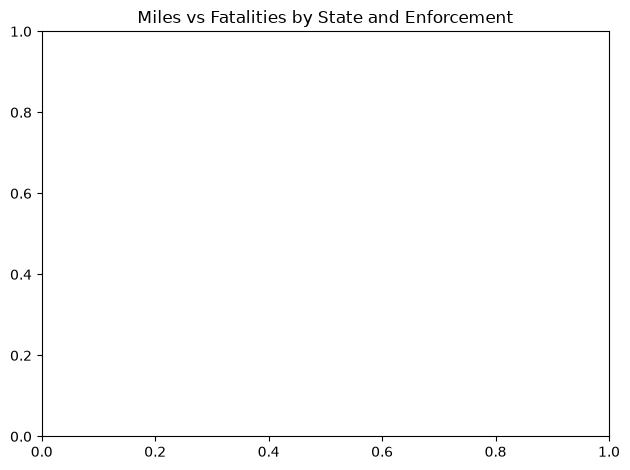

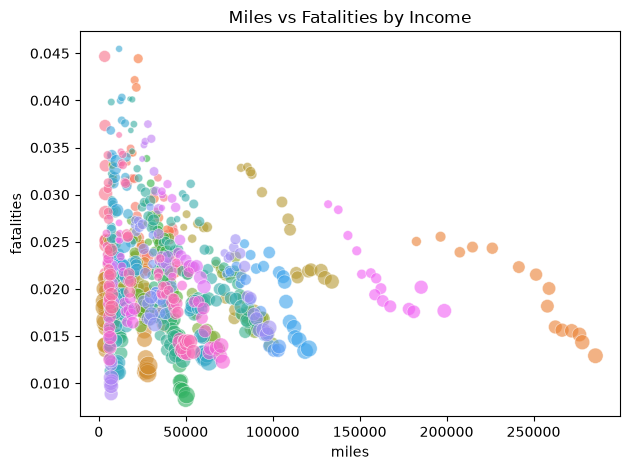

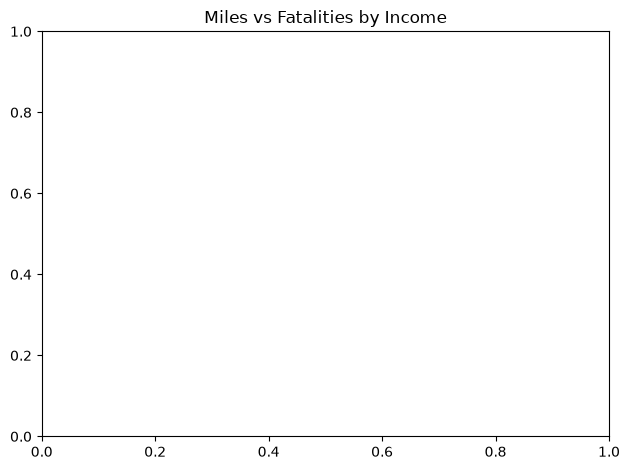

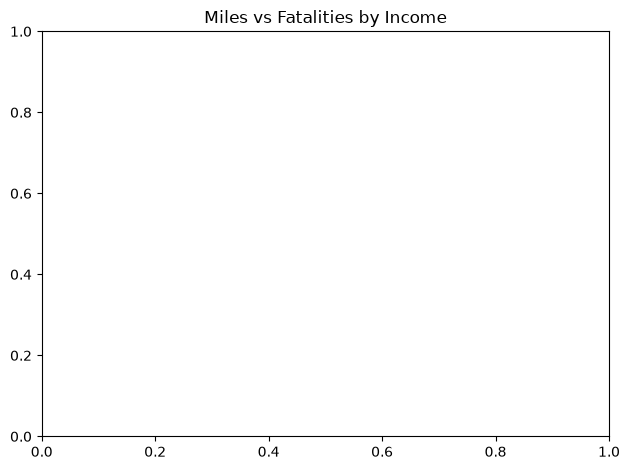

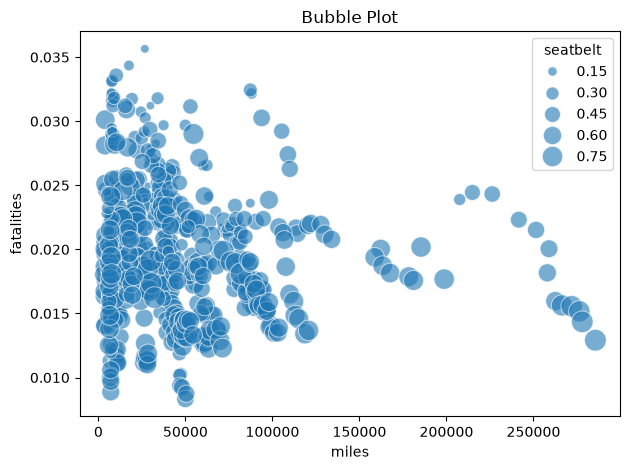

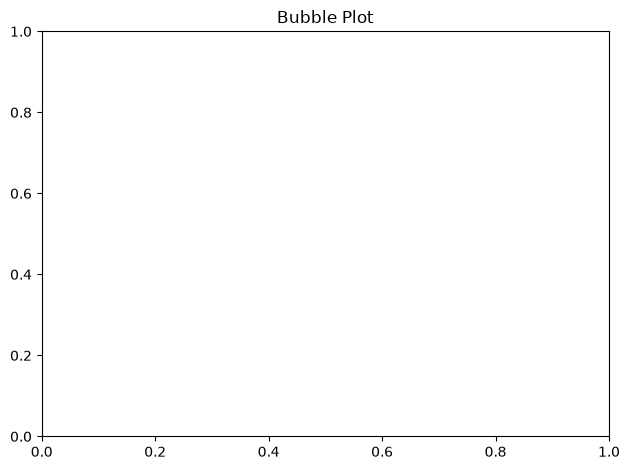

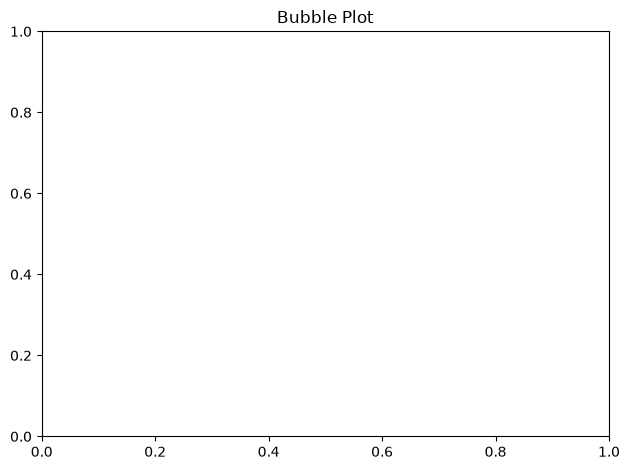

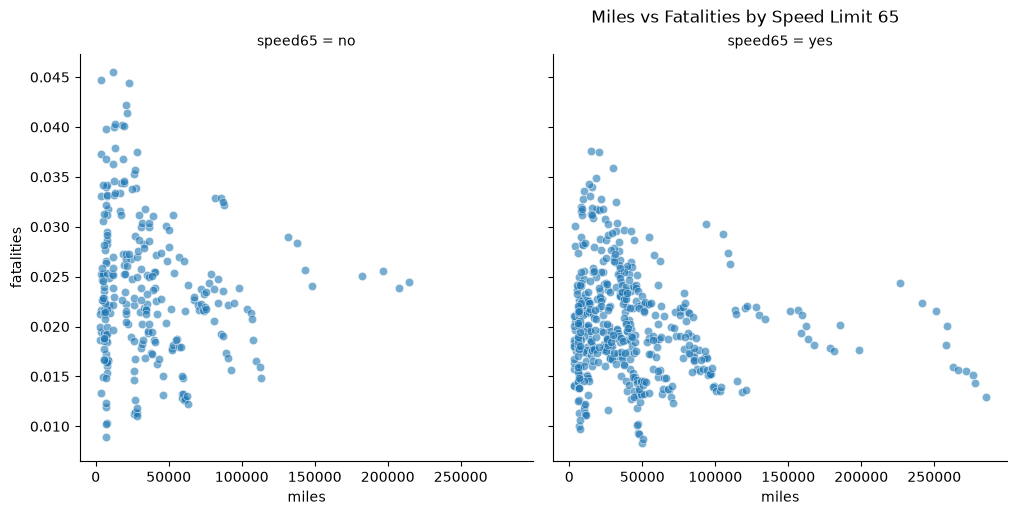

<Figure size 640x480 with 0 Axes>

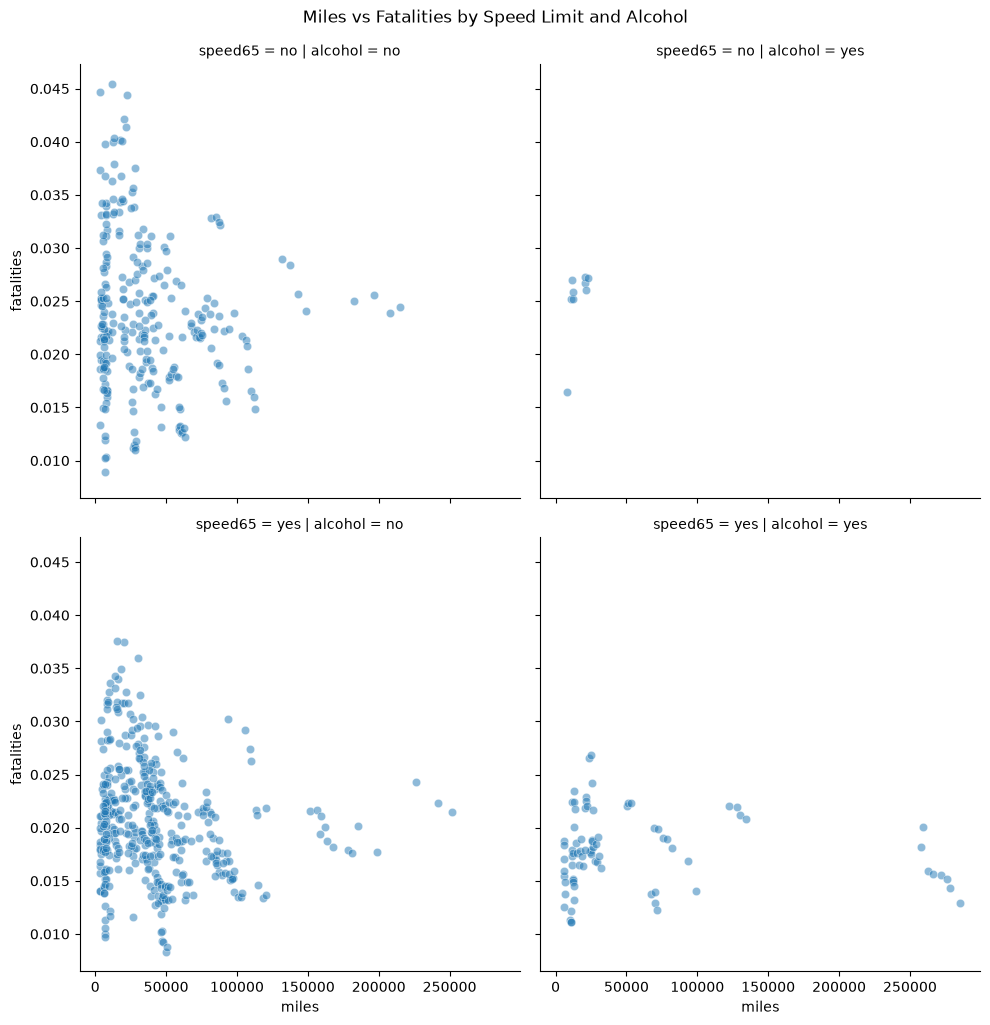

<Figure size 640x480 with 0 Axes>

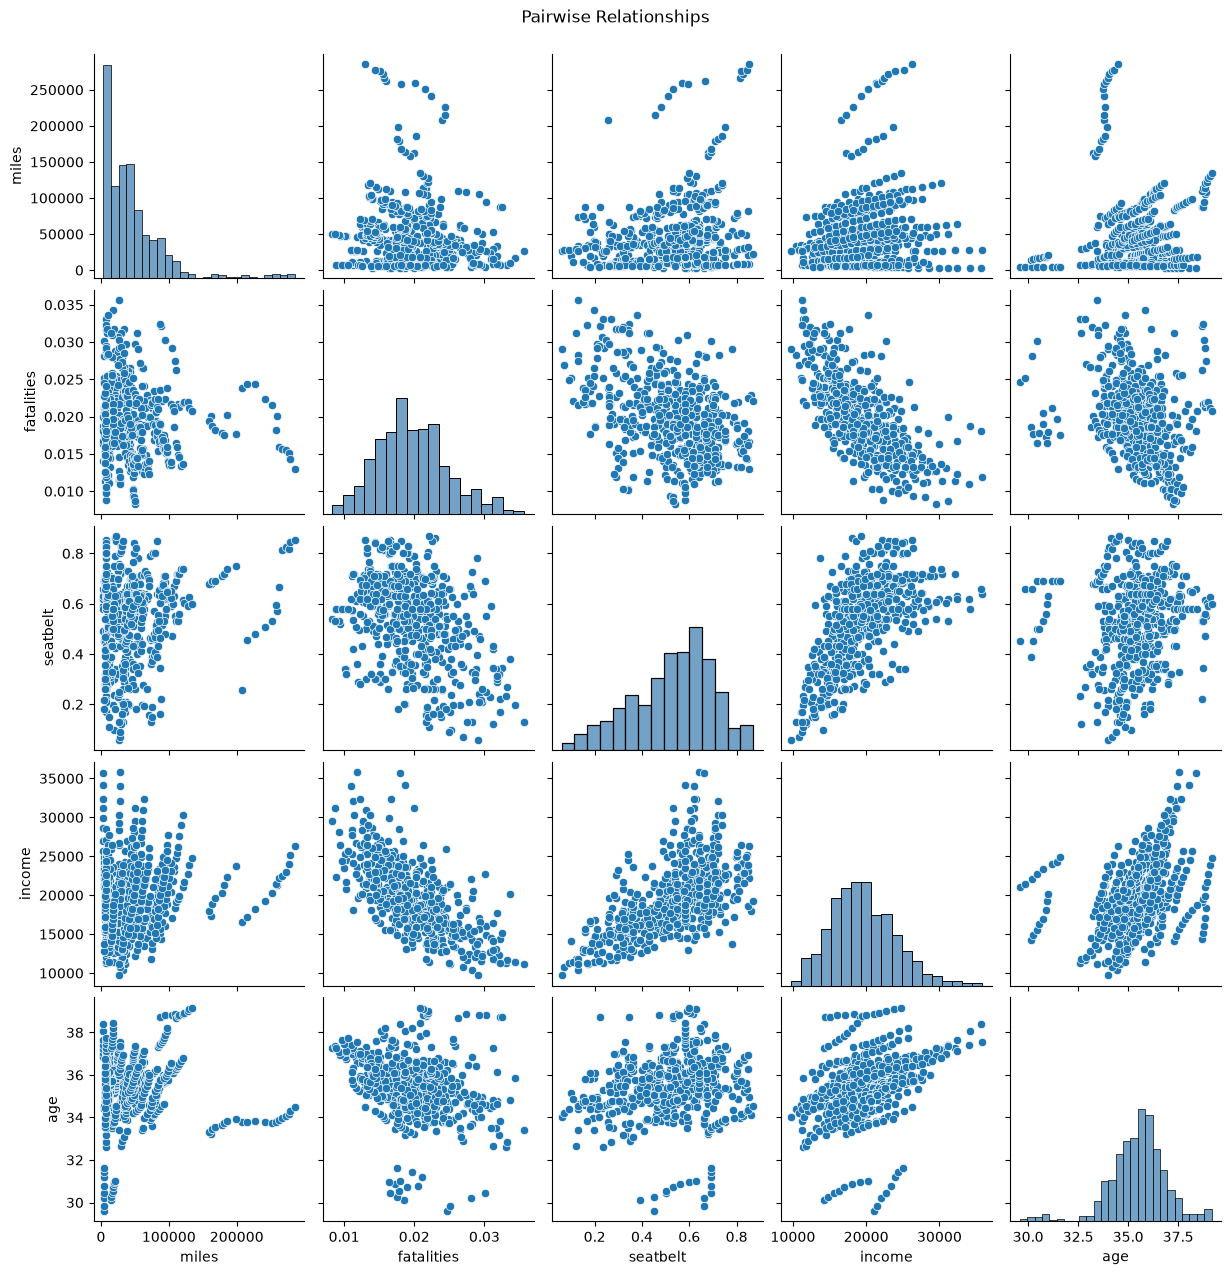

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("\nNUMERICAL VARIABLES:", numeric_cols)
print("CATEGORICAL VARIABLES:", categorical_cols)
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", legend=False, alpha=.75)
plt.title("Miles vs Fatalities by State"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by State"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by State"); plt.tight_layout(); plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", style="enforce", alpha=.75, legend=False)
plt.title("Miles vs Fatalities by State and Enforcement"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by State and Enforcement"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by State and Enforcement"); plt.tight_layout(); plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", hue="state", size="income", sizes=(15,180), alpha=.6, legend=False)
plt.title("Miles vs Fatalities by Income"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by Income"); plt.tight_layout(); plt.show()
plt.title("Miles vs Fatalities by Income"); plt.tight_layout(); plt.show()
sns.scatterplot(data=df, x="miles", y="fatalities", size="seatbelt", sizes=(20,250), alpha=.6)
plt.title("Bubble Plot"); plt.tight_layout(); plt.show()
plt.title("Bubble Plot"); plt.tight_layout(); plt.show()
plt.title("Bubble Plot"); plt.tight_layout(); plt.show()
sns.relplot(data=df, x="miles", y="fatalities", col="speed65", col_wrap=3, kind="scatter", alpha=.6)
plt.suptitle("Miles vs Fatalities by Speed Limit 65", y=1.02); plt.show()
plt.suptitle("Miles vs Fatalities by Speed Limit 65", y=1.02); plt.show()
sns.relplot(data=df, x="miles", y="fatalities", col="alcohol", row="speed65", kind="scatter", alpha=.5)
plt.suptitle("Miles vs Fatalities by Speed Limit and Alcohol", y=1.02); plt.show()
plt.suptitle("Miles vs Fatalities by Speed Limit and Alcohol", y=1.02); plt.show()
pairs = [c for c in ["miles","fatalities","seatbelt","income","age"] if c in df]
sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"}); plt.suptitle("Pairwise Relationships", y=1.02); plt.show()

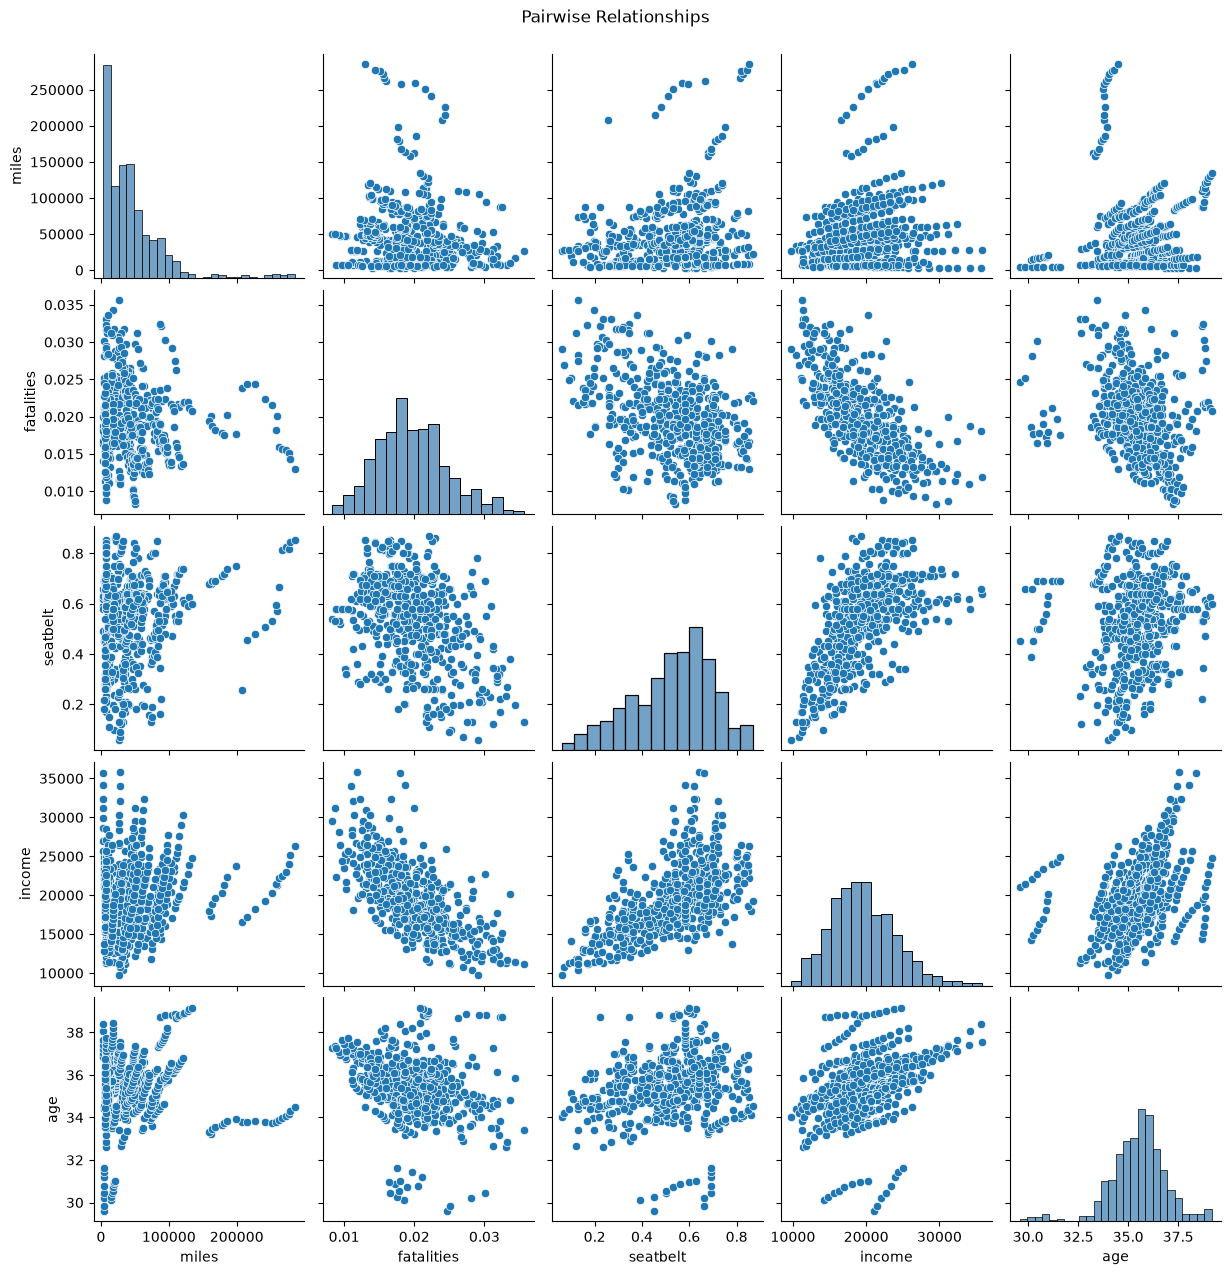

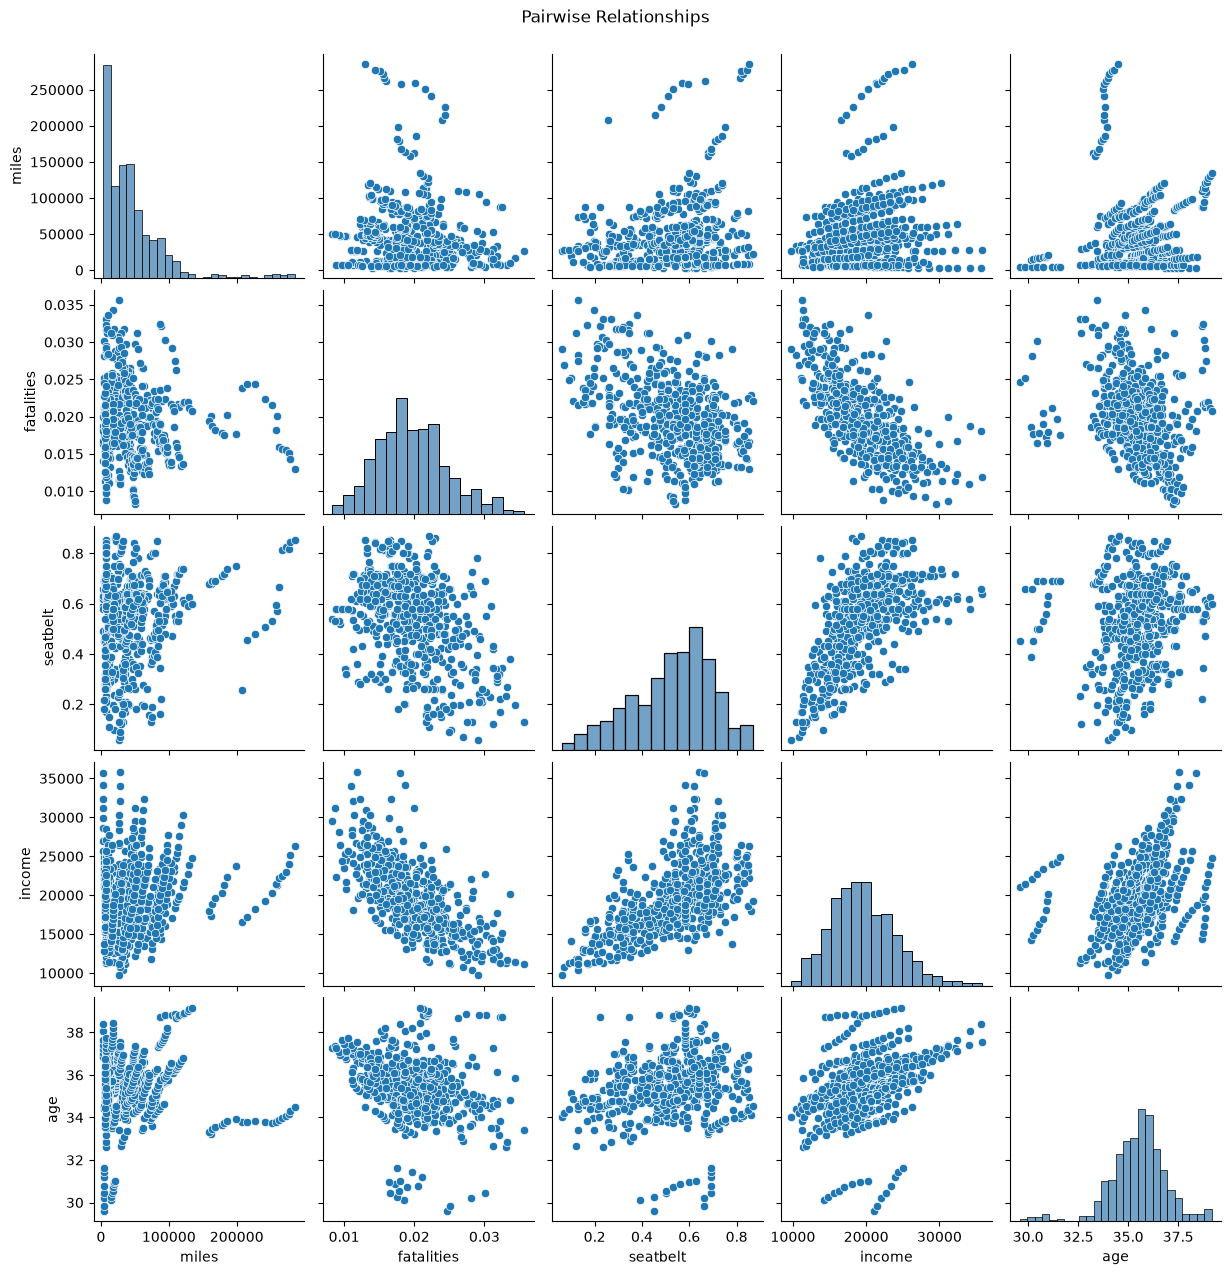

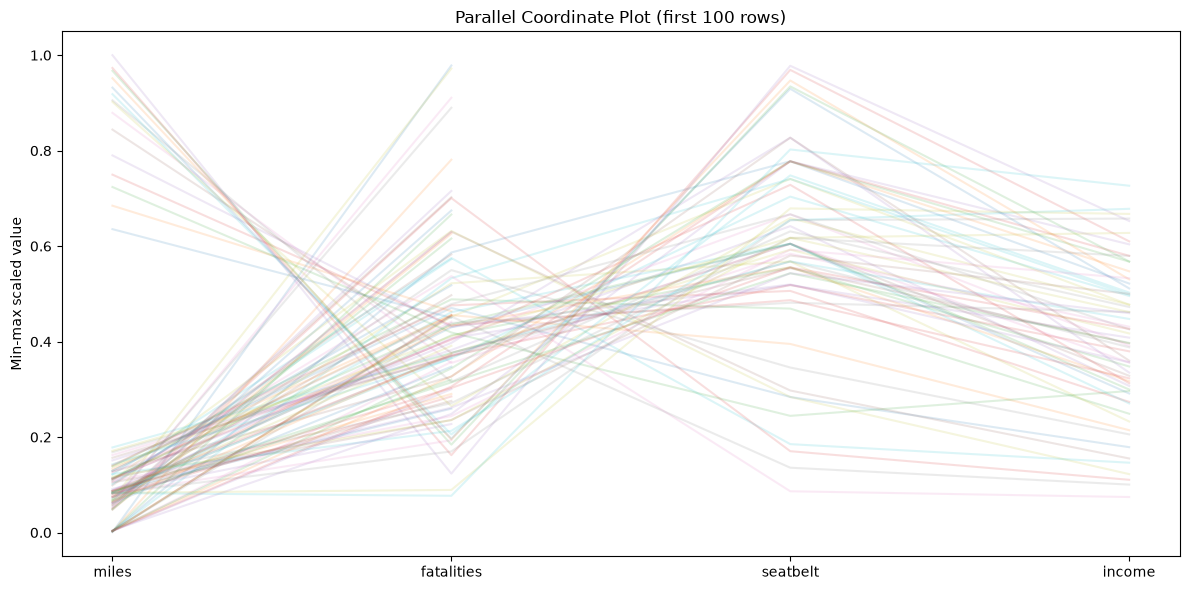

In [3]:
sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"}); plt.suptitle("Pairwise Relationships", y=1.02); plt.show()
sns.pairplot(df[pairs].dropna(), diag_kws={"color": "steelblue"}); plt.suptitle("Pairwise Relationships", y=1.02); plt.show()
parallel_cols = [c for c in ["miles","fatalities","seatbelt","income"] if c in df]
if len(parallel_cols)>1:
    scaled = df[parallel_cols].apply(lambda s: (s-s.min())/(s.max()-s.min()) if s.max()!=s.min() else 0)
    plt.figure(figsize=(12,6))
    for _, row in scaled.head(100).iterrows():
        plt.plot(range(len(parallel_cols)), row.values, alpha=.15)
    plt.xticks(range(len(parallel_cols)), parallel_cols)
    plt.title("Parallel Coordinate Plot (first 100 rows)"); plt.ylabel("Min-max scaled value"); plt.tight_layout(); plt.show()